# Integrable model for resonance
This notebook illustrates how to apply canonical transformations in `celmech` to derive and work with the integrable model for mean motion resonances between pairs of planets described in [Hadden (2019)](https://ui.adsabs.harvard.edu/abs/2019AJ....158..238H/abstract).

In [1]:
import celmech as cm
import rebound as rb
import sympy as sp
import numpy as np
from matplotlib import pyplot as plt
from celmech.disturbing_function import get_fg_coefficients
from celmech.canonical_transformations import CanonicalTransformation
from celmech.miscellaneous import truncated_expansion

Take a Hamiltonian for a 5:3 MMR as our starting point

In [2]:
def get_pham(j,k):
    sim = rb.Simulation()
    sim.add(m=1)
    sim.add(m=1e-5,P=1,e=0.1,pomega=np.pi)
    sim.add(m=1e-5,P = j/(j-k),e=0.1)
    return cm.PoincareHamiltonian(cm.Poincare.from_Simulation(sim))
jres,kres = 5,2
pham = get_pham(jres,kres)
pham.add_MMR_terms(jres,kres,inclinations=False)
pham.H

                                                                ⎛⎛             ↪
  C_{(5,-3,-1,-1,0,0)}_{1,2})__{(0,0,0,0),(0,0)}(\alpha⋅G⋅m₁⋅m₂⋅⎜⎜- ────────── ↪
                                                                ⎜⎜    ________ ↪
                                                                ⎝⎝  ╲╱ \Lambda ↪
- ──────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪      η₁⋅η₂                                 κ₁⋅κ₂               ⎞             ↪
↪ ───────────────────────── + ───────────────────────────────────⎟⋅cos(3⋅λ₁ -  ↪
↪ _______   _______________     _______________   _______________⎟             ↪
↪ _{1,0} ⋅╲╱ \Lambda_{2,0}    ╲╱ \Lambda_{1,0} ⋅╲╱ \Lambda_{2,0} ⎠             ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                          

### Transformations
Now we'll use the `CanonicalTransformation` class to affect a series of transformations. We'll keep track of each individal transformation so that we can create a composite transformation that takes us from our original variables to our final target variables and vice versa. The order of transfromations is slightly different than those in [Hadden (2019)](https://ui.adsabs.harvard.edu/abs/2019AJ....158..238H/abstract) but our ultimate result will be the same

In [3]:
transformations  = []

First, we'll convert to  $\delta \Lambda_i = \Lambda_{i}-\Lambda_{i,0}$  

In [4]:
# transform from Lambdas to delta-Lambdas
ct_dL = CanonicalTransformation.Lambdas_to_delta_Lambdas(pham)
transformations.append(ct_dL)


ham_dL = ct_dL.old_to_new_hamiltonian(pham)
dLambdas = ham_dL.qp_vars[ham_dL.N_dof::3]


# Exapnd the Hamiltonian to 2nd order in delta-Lambdas
ham_dL.H = truncated_expansion(
    ham_dL.H,
    {1:dLambdas},
    2
)
ham_dL.H

                                                                ⎛⎛             ↪
  C_{(5,-3,-1,-1,0,0)}_{1,2})__{(0,0,0,0),(0,0)}(\alpha⋅G⋅m₁⋅m₂⋅⎜⎜- ────────── ↪
                                                                ⎜⎜    ________ ↪
                                                                ⎝⎝  ╲╱ \Lambda ↪
- ──────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪      η₁⋅η₂                                 κ₁⋅κ₂               ⎞             ↪
↪ ───────────────────────── + ───────────────────────────────────⎟⋅cos(3⋅λ₁ -  ↪
↪ _______   _______________     _______________   _______________⎟             ↪
↪ _{1,0} ⋅╲╱ \Lambda_{2,0}    ╲╱ \Lambda_{1,0} ⋅╲╱ \Lambda_{2,0} ⎠             ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                          

Now we'll transform to new angle variables $Q_1 = \lambda_1 - \lambda_2$ and 
$$
\begin{align}
Q_2 &= \frac{1}{2}(5\lambda_2-3\lambda_1)\\
Q_3 &= \frac{1}{2}(5\lambda_2-3\lambda_1)-\varpi_1\\
Q_4 &= \frac{1}{2}(5\lambda_2-3\lambda_1)-\varpi_2
\end{align}
$$


In [5]:
# Construct transformation to resonant angles
A = np.eye(pham.N_dof,dtype = object)
A[0,:2]= 1,-1
A[1:,:2]= -3/sp.S(2),5/sp.S(2)

# We use this temporary transformation to build the transformation we acutally want,
# which goes from delta-Lambdas to resonant variables
ct_temp = CanonicalTransformation.from_poincare_angles_matrix(pham.state,A)
Lambdas = pham.qp_vars[pham.N_dof::3]
Lambda_to_dL = dict(zip(Lambdas,dLambdas))
dL_to_Lambda = dict(zip(Lambdas,dLambdas))
n2o = { key:(val.xreplace(Lambda_to_dL)) for key,val in ct_temp.new_to_old_rule.items()}
o2n = { key.xreplace(dL_to_Lambda):val for key,val in ct_temp.old_to_new_rule.items()}
# the transformation to resonant variables
ct_res = CanonicalTransformation(
    ham_dL.qp_vars,
    ct_temp.new_qp_vars,
    o2n,
    n2o,
    old_to_new_simplify = lambda x: x.func(*[sp.trigsimp(arg) for arg in x.args])
)

transformations.append(ct_res)

ham_res = ct_res.old_to_new_hamiltonian(ham_dL)
ham_res.H

                                                                               ↪
                                                                               ↪
                                                              ____   ____      ↪
  2⋅C_{(5,-3,-1,-1,0,0)}_{1,2})__{(0,0,0,0),(0,0)}(\alpha⋅G⋅╲╱ P₃ ⋅╲╱ P₄ ⋅m₁⋅m ↪
- ──────────────────────────────────────────────────────────────────────────── ↪
                           _______________   _______________                   ↪
                         ╲╱ \Lambda_{1,0} ⋅╲╱ \Lambda_{2,0} ⋅a_{2,0}           ↪

↪                                                                              ↪
↪                                                                              ↪
↪                                                                              ↪
↪ ₂⋅cos(Q₃ + Q₄)   2⋅C_{(5,-3,-2,0,0,0)}_{1,2})__{(0,0,0,0),(0,0)}(\alpha⋅G⋅P₃ ↪
↪ ────────────── - ─────────────────────────────────────────────────────────── ↪
↪                          

Next, we switch from 'polar'-style AA variables $(Q_i,P_i)$ to cartesian-style variables $(y_i,x_i) = \sqrt{2P_i}\times(\sin Q_i,\cos Q_i)$ for $i=3,4$.

In [6]:
ct_pq2xy = CanonicalTransformation.polar_to_cartesian(ham_res.qp_vars,indices=[2,3])
transformations.append(ct_pq2xy)
ham_res_xy = ct_pq2xy.old_to_new_hamiltonian(ham_res)
ham_res_xy.H

                                                                               ↪
                                                                               ↪
                                                                               ↪
                                                                               ↪
  C_{(5,-3,-1,-1,0,0)}_{1,2})__{(0,0,0,0),(0,0)}(\alpha⋅G⋅m₁⋅m₂⋅(x₁⋅x₂ - y₁⋅y₂ ↪
- ──────────────────────────────────────────────────────────────────────────── ↪
                     _______________   _______________                         ↪
                   ╲╱ \Lambda_{1,0} ⋅╲╱ \Lambda_{2,0} ⋅a_{2,0}                 ↪

↪                                                                              ↪
↪                                                                              ↪
↪                                                                              ↪
↪                                                                  ⎛  2     2⎞ ↪
↪ )   C_{(5,-3,-2,0,0,0)}_{

Now make the rotation transformation introduced in Eq. 15 of [Hadden (2019)](https://ui.adsabs.harvard.edu/abs/2019AJ....158..238H/abstract)

In [7]:

from celmech.disturbing_function import get_fg_coefficients
f,g = sp.symbols("f,g",real=True)
mu1,mu2 = sp.symbols("mu(1:3)")
a10,a20 = [cm.poincare._get_a0_symbol(i) for i in (1,2)]
alpha = a10/a20
fTilde = sp.sqrt((mu1+mu2)/(mu1 * sp.sqrt(alpha))) * f
gTilde = sp.sqrt((mu1+mu2)/ mu2) * g

tr_params = dict(zip((f,g),get_fg_coefficients(jres,kres)))
for s in (mu1,mu2,a10,a20):
    tr_params[s] = pham.H_params[s]
tr_params

s,c = sp.sin(sp.atan2(gTilde,fTilde)),sp.cos(sp.atan2(gTilde,fTilde))
M = sp.Matrix([
    [c,s],
    [-s,c]
])
Minv = sp.Matrix([
    [c,-s],
    [s,c]
])

y1,y2 = ham_res_xy.qp_vars[2:4]
x1,x2 = ham_res_xy.qp_vars[ham_res_xy.N_dof + 2:ham_res_xy.N_dof + 4]
u1,u2,v1,v2 = sp.symbols("u(1:3),v(1:3)",real=True)

newvars = sp.symbols("q(1:3)") + (v1,v2) + sp.symbols("q(5:7)") + sp.symbols("p(1:3)") + (u1,u2) + sp.symbols("p(5:7)") 

forward_rule =dict(zip(ham_res_xy.qp_vars,newvars))
forward_rule.update(dict(zip([x1,x2],(Minv @ sp.Matrix([u1,u2])))))
forward_rule.update(dict(zip([y1,y2],(Minv @ sp.Matrix([v1,v2])))))

inverse_rule = dict(zip(newvars,ham_res_xy.qp_vars))
inverse_rule.update(dict(zip([u1,u2],(M @ sp.Matrix([x1,x2])))))
inverse_rule.update(dict(zip([v1,v2],(M @ sp.Matrix([y1,y2])))))

ct_xy_to_uv = CanonicalTransformation(
    ham_res_xy.qp_vars,
    newvars,
    forward_rule,
    inverse_rule,
    params = tr_params
)
transformations.append(ct_xy_to_uv)
ham_res_uv = ct_xy_to_uv.old_to_new_hamiltonian(ham_res_xy)
ham_res_uv.H

                                                                               ↪
                                                                               ↪
                                                                               ↪
                                                                               ↪
                                                                ⎛⎛             ↪
                                                                ⎜⎜             ↪
                                                                ⎜⎜             ↪
                                                                ⎜⎜             ↪
  C_{(5,-3,-1,-1,0,0)}_{1,2})__{(0,0,0,0),(0,0)}(\alpha⋅G⋅m₁⋅m₂⋅⎜⎜──────────── ↪
                                                                ⎜⎜      ______ ↪
                                                                ⎜⎜     ╱  2    ↪
                                                                ⎜⎜    ╱  g ⋅(μ ↪
                            

Finally, we rescale our Hamiltonian and actions by $\Lambda_{2,0}$

In [8]:
L20 = pham.Lambda0s[2]
ct_rescale = CanonicalTransformation.rescale_transformation(
    ham_res_uv.qp_pairs,
    1 /L20,
    cartesian_pairs=[2,3],
    params = {L20:pham.H_params[L20]}
)
transformations.append(ct_rescale)

ct_all = CanonicalTransformation.composite(transformations)
ham_res_uv_scaled = ct_rescale.old_to_new_hamiltonian(ham_res_uv)

Let's look at our variables and how the relate to the original ones:

In [9]:
for q,p in ham_res_uv_scaled.qp_pairs:
    display(p,sp.trigsimp(ct_all.new_to_old(p).expand()))

p₁

     5⋅Λ₁              3⋅Λ₂         5⋅\Lambda_{1,0}   3
─────────────── + ─────────────── - ─────────────── - ─
2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}   2

p₂

                                                            2                  ↪
     Λ₁              Λ₂         \Lambda_{1,0}             η₁                η₂ ↪
───────────── + ───────────── - ───────────── - 1 - ─────────────── - ──────── ↪
\Lambda_{2,0}   \Lambda_{2,0}   \Lambda_{2,0}       2⋅\Lambda_{2,0}   2⋅\Lambd ↪

↪ 2                 2                 2                 2                 2    ↪
↪                 κ₁                κ₂                ρ₁                ρ₂     ↪
↪ ─────── - ─────────────── - ─────────────── - ─────────────── - ──────────── ↪
↪ a_{2,0}   2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}   2⋅\Lambda_{2 ↪

↪               2                 2      
↪             σ₁                σ₂       
↪ ─── - ─────────────── - ───────────────
↪ ,0}   2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}

u₁

...

              ___________                                                      ↪
             ╱   2     2      ________                                         ↪
            ╱  η₁    κ₁      ╱ μ₁         ⎛  3⋅λ₁   5⋅λ₂                ⎞      ↪
    √2⋅g⋅  ╱   ─── + ─── ⋅  ╱  ── + 1 ⋅cos⎜- ──── + ──── + atan2(η₁, κ₁)⎟      ↪
         ╲╱     2     2   ╲╱   μ₂         ⎝   2      2                  ⎠      ↪
- ───────────────────────────────────────────────────────────────────────── +  ↪
                          _________________________________________________    ↪
                         ╱  2             _________  2     _________  2        ↪
    _______________     ╱  g ⋅μ₁    2   ╲╱ a_{2,0} ⋅f    ╲╱ a_{2,0} ⋅f ⋅μ₂     ↪
  ╲╱ \Lambda_{2,0} ⋅   ╱   ───── + g  + ────────────── + ─────────────────     ↪
                      ╱     μ₂             _________        _________          ↪
                    ╲╱                   ╲╱ a_{1,0}       ╲╱ a_{1,0} ⋅μ₁       ↪

↪                          

p₅

        2                 2      
      ρ₁                σ₁       
─────────────── + ───────────────
2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}

p₆

        2                 2      
      ρ₂                σ₂       
─────────────── + ───────────────
2⋅\Lambda_{2,0}   2⋅\Lambda_{2,0}

## Reduction to a single degree of freedom:

If we were to immediately apply a reduction to our current Hamiltonian, we would still have two degrees of freedom. That's because the rotation transfromation doesn't entirely eliminate the pair $(v_2,u_2)$ which are equivalent to $\sqrt{2\Psi} (\sin\psi,\cos\psi)$ in the notation of [Hadden (2019)](https://ui.adsabs.harvard.edu/abs/2019AJ....158..238H/abstract). But we can see that the coefficients terms involving $\psi$ are very small in the Hamiltonian as follows:

In [10]:
psi,Psi = sp.symbols("psi,Psi")
v2u2_to_psiPsi = CanonicalTransformation.cartesian_to_polar(
    ham_res_uv_scaled.qp_vars,
    [ham_res_uv_scaled.qp_vars.index(sp.Symbol("v2",real=True)),],
    polar_symbol_pairs=[(psi,Psi),]
)
v2u2_to_psiPsi.old_to_new(ham_res_uv_scaled.N_H).expand()

                                                                               ↪
1.80139933738454e-7⋅√2⋅√Ψ⋅u₁⋅cos(ψ) - 1.80139933738494e-7⋅√2⋅√Ψ⋅v₁⋅sin(ψ) - 60 ↪

↪                2                                                             ↪
↪ .484088078689⋅Ψ  + 61.7958877056255⋅Ψ⋅p₁ - 120.968176157378⋅Ψ⋅p₂ - 120.96817 ↪

↪                                                            2                 ↪
↪ 6157378⋅Ψ⋅p₅ - 120.968176157378⋅Ψ⋅p₆ - 60.484088078689⋅Ψ⋅u₁  - 60.4840880786 ↪

↪        2                                                                     ↪
↪ 89⋅Ψ⋅v₁  + 1.13840749599092e-6⋅Ψ⋅cos(2⋅ψ) + 0.000295039399454086⋅Ψ - 16.8287 ↪

↪             2                                                                ↪
↪ 166220165⋅p₁  + 61.7958877056255⋅p₁⋅p₂ + 61.7958877056255⋅p₁⋅p₅ + 61.7958877 ↪

↪                                      2                         2             ↪
↪ 056255⋅p₁⋅p₆ + 30.8979438528127⋅p₁⋅u₁  + 30.8979438528127⋅p₁⋅v₁  + 2.5130783 ↪

↪                     

In [11]:
h_final = v2u2_to_psiPsi.old_to_new_hamiltonian(ham_res_uv_scaled)
transformations.append(v2u2_to_psiPsi)
h_final.N_H.expand()

                                                                               ↪
1.8013993373844e-7⋅√2⋅√Ψ⋅u₁⋅cos(ψ) - 1.80139933738433e-7⋅√2⋅√Ψ⋅v₁⋅sin(ψ) + 6.7 ↪

↪                                                       2                      ↪
↪ 762635780344e-21⋅√2⋅ⅈ⋅√Ψ⋅v₁⋅cos(ψ) - 60.484088078689⋅Ψ  + 61.7958877056255⋅Ψ ↪

↪                                                                              ↪
↪ ⋅p₁ - 120.968176157378⋅Ψ⋅p₂ - 120.968176157378⋅Ψ⋅p₅ - 120.968176157378⋅Ψ⋅p₆  ↪

↪                       2                       2                              ↪
↪ - 60.484088078689⋅Ψ⋅u₁  - 60.484088078689⋅Ψ⋅v₁  + 1.13840749599103e-6⋅Ψ⋅cos( ↪

↪                                                    2                         ↪
↪ 2⋅ψ) + 0.000295039399455632⋅Ψ - 16.8287166220165⋅p₁  + 61.7958877056255⋅p₁⋅p ↪

↪                                                                              ↪
↪ ₂ + 61.7958877056255⋅p₁⋅p₅ + 61.7958877056255⋅p₁⋅p₆ + 30.8979438528127⋅p₁⋅u₁ ↪

↪ 2                   

Let's exploit some standard `sympy` tricks to make a new Hamiltonian in which we simply drop these terms:

In [12]:
full_ham = h_final.H.expand()
truncated_ham = full_ham.func(*[arg for arg in full_ham.args if not psi in arg.free_symbols])

We can see the difference between the full Hamiltonian and our truncated version:

In [13]:
(full_ham-truncated_ham).xreplace(h_final.H_params)

1.80139933738359e-7⋅√2⋅√Ψ⋅u₁⋅cos(ψ) - 1.80139933738386e-7⋅√2⋅√Ψ⋅v₁⋅sin(ψ) + 1. ↪

↪ 13840749599114e-6⋅Ψ⋅cos(2⋅ψ)

Now we'll simply overwrite the Hamiltonian with our truncted version. After doing so, we call `_update()` to register our changes.

In [14]:
h_final.H = truncated_ham
h_final._update()

Our final Hamiltionian still has 6 degrees of freedom, as it tracks the ignorable degrees:

In [15]:
h_final.N_dof

6

We can convert this to a reduced Hamiltonian as follows:

In [16]:
h_final_reduced = cm.hamiltonian.reduce_hamiltonian(h_final)

Now we have a 1-dof integrable Hamiltonian in our variables $(v_1,u_1)$:

In [17]:
h_final_reduced.N_dof

1

Lets look at our Hamiltonian expressed in our canonical variables:

In [18]:
h_final_reduced.N_H

                     4                      2   2                       2      ↪
- 15.1210220196722⋅u₁  - 30.2420440393445⋅u₁ ⋅v₁  + 0.557289701272822⋅u₁  - 15 ↪

↪                  4                       2                   
↪ .1210220196722⋅v₁  + 0.558012386843441⋅v₁  - 4.53976530598397

At this point we could introduce a further rescaling of our Hamiltonian *a la* [Murray & Dermotte (1999, Chapter 8)](https://ui.adsabs.harvard.edu/abs/1999ssd..book.....M/abstract) to derive a 1-parameter Hamiltonian that does not depend on the planets' masses. We won't do this here, but simply note that `CanonicalTransformation.rescale_transformation` provides the neccessary tool to do so.

### Equilibrium points and phase space diagram
Now that we have a 1-dof model, lets determine the fixed points of the Hamiltonian and construct a phase space diagram.

In [19]:
# store equlibria at (v1,u1) = (v1_eq,0)
eq_v1_values = sp.roots(
    h_final_reduced.N_flow.xreplace({u1:0})[1],
    v1
)
eq_pts_v1 = [(float(v1_val),0.0) for v1_val in eq_v1_values]

# now determine the stability of the equilibrium points:
    # hyperbolic (unstable) equilibria will have real eigenvalues
    # elliptic equilibria have imaginary eigenvalues
print("Eigenvalues of (v1_eq,0) points:")
for pt in eq_pts_v1:
    eigs = np.linalg.eigvals(h_final_reduced.jacobian_func(*pt))
    print("point: ", pt,"eigenvalues: ",eigs)


# store equlibria at (v1,u1) = (0,u1_eq)
eq_u1_values = sp.roots(
    h_final_reduced.N_flow.xreplace({v1:0})[0],
    u1
)
eq_pts_u1 = [(0.0,float(u1_val)) for u1_val in eq_u1_values]

print("Eigenvalues of (0,u1_eq) points:")
for pt in eq_pts_u1:
    eigs = np.linalg.eigvals(h_final_reduced.jacobian_func(*pt))
    print("point: ", pt,"eigenvalues: ",eigs)


Eigenvalues of (v1_eq,0) points:
point:  (-0.13583645813462542, 0.0) eigenvalues:  [ 0.+0.05679912j -0.-0.05679912j]
point:  (0.13583645813462542, 0.0) eigenvalues:  [-0.+0.05679912j  0.-0.05679912j]
point:  (0.0, 0.0) eigenvalues:  [-0.+1.11530185j  0.-1.11530185j]
Eigenvalues of (0,u1_eq) points:
point:  (0.0, -0.13574846828406661) eigenvalues:  [ 0.05676233 -0.05676233]
point:  (0.0, 0.13574846828406661) eigenvalues:  [ 0.05676233 -0.05676233]
point:  (0.0, 0.0) eigenvalues:  [-0.+1.11530185j  0.-1.11530185j]


In [20]:
# make plot range 1.5 times the size of max equlibrium point
uv_range = float(1.25 * np.max(list(eq_u1_values.keys()))) 
X,Y = np.meshgrid(
    np.linspace(-0.1,1,200) * uv_range,
    np.linspace(-1,1,200) * uv_range
)

E = h_final_reduced.H_func(X,Y)
E_ell = float(h_final_reduced.H_func(*eq_pts_v1[0]))
E_sx = float(h_final_reduced.H_func(*eq_pts_u1[0]))


Text(0, 0.5, '$u_1$')

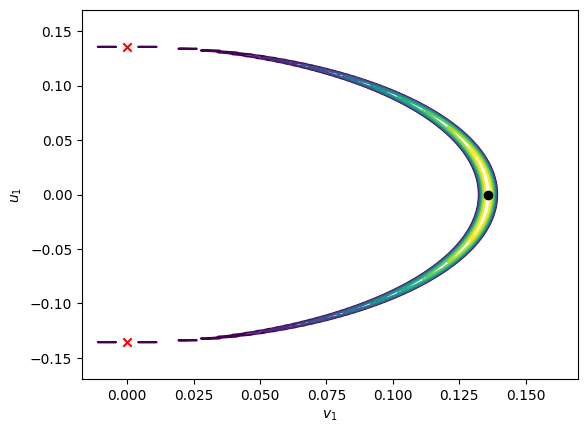

In [21]:
plt.contour(X,Y,E,levels = np.sort(np.linspace(E_ell,E_sx,10)[1:]))
plt.scatter(*eq_pts_v1[1],color='k',zorder=99)
plt.scatter(*eq_pts_u1[0],color='r',marker='x',zorder=99)
plt.scatter(*eq_pts_u1[1],color='r',marker='x',zorder=99)
plt.xlabel(r"$v_1$")
plt.ylabel(r"$u_1$")

Let's use our 1-dof model to initialize some N-body simulations. We'll initialize one simulation at the predicted resonant equilibrium and another slightly away from the center of the resonance so that is has some libration amplitude. In order to initialize our simulations we'll make a composite canonical transformation that takes us all the way back to our original `celmech.Poincare` variables and then use the `toSimulation` method to get a `rebound` N-body simulation.

In [22]:
ct_composite = CanonicalTransformation.composite(transformations)

In [23]:
# We'll our second initial condition by rotating the elliptic equilibrium by 30deg in the u-v plane
c,s = np.cos(30 * np.pi / 180),np.sin(30 * np.pi / 180)
librating_ics = np.array([[c,-s],[s,c]]) @ eq_pts_v1[1]

In [24]:
h_final_reduced.state.values = eq_pts_v1[1]
equilibrium_in_poincare_vars = np.real(ct_composite.new_to_old_array(
    h_final_reduced.full_values
))

h_final_reduced.state.values = librating_ics
librating_ics_in_poincare_vars =  np.real(ct_composite.new_to_old_array(
    h_final_reduced.full_values
))


In [25]:
pham.state.values = equilibrium_in_poincare_vars
eq_sim = pham.state.to_Simulation()

pham.state.values = librating_ics_in_poincare_vars
librating_sim = pham.state.to_Simulation()

times = np.linspace(0,500,250) * eq_sim.particles[1].P
u1_nbody_eq,v1_nbody_eq = np.zeros((2,times.shape[0]))
u1_nbody_librating,v1_nbody_librating = np.zeros((2,times.shape[0]))

i_u1 = ct_composite.new_qp_vars.index(u1)
i_v1 = ct_composite.new_qp_vars.index(v1)
for i,t in enumerate(times):
    eq_sim.integrate(t)
    librating_sim.integrate(t)
    
    pvars = cm.Poincare.from_Simulation(eq_sim)
    vals = ct_composite.old_to_new_array(pvars.values)
    u1_nbody_eq[i] = vals[i_u1]
    v1_nbody_eq[i] = vals[i_v1]

    pvars = cm.Poincare.from_Simulation(librating_sim)
    vals = ct_composite.old_to_new_array(pvars.values)
    u1_nbody_librating[i] = vals[i_u1]
    v1_nbody_librating[i] = vals[i_v1]


In the plot below we see that the librating trajectory shows an oscillating resonant angle with an amplitude of about $\sim 50^\circ$. The equlibrium trajectory shows small oscillations ($\sim 5^\circ$ in amplitude), rather than remaining constant. This discrepancy is, in part, due to the fact that we have not applied a correction from our osculating canonical elements to the mean elements implicitly used by our reduced Hamiltonian model (see, e.g., [here](https://celmech.readthedocs.io/en/latest/canonical_transformations.html#lie-series-transformations)). Some of the discrepancy is probably also owed to truncating our expansion of the disturbing function at second order in eccentricity.

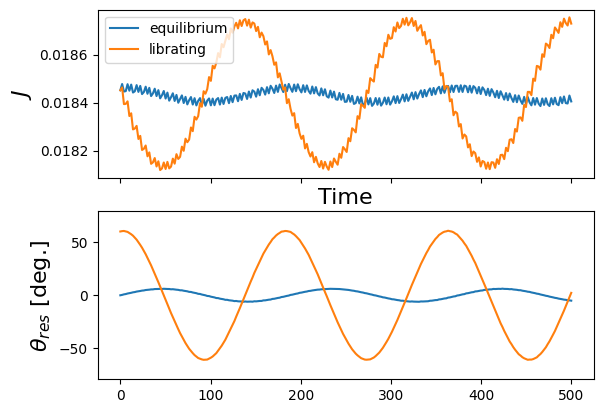

In [26]:
fig,ax = plt.subplots(2,1,sharex=True)
J_eq = u1_nbody_eq**2 + v1_nbody_eq**2
J_lib = u1_nbody_librating**2 + v1_nbody_librating**2
## theta_res is 5lambda_out - 3\lambda_in - \arg{Z}
## note factor of 2x difference between theta_res and theta in Hadden (2019)
theta_res_eq = 180*(np.mod(2*np.arctan2(u1_nbody_eq,v1_nbody_eq) + np.pi,2*np.pi)-np.pi)/np.pi
theta_res_lib = 180*(np.mod(2*np.arctan2(u1_nbody_librating,v1_nbody_librating) + np.pi,2*np.pi)-np.pi)/np.pi


ax[0].plot(times,J_eq,label='equilibrium')
ax[0].plot(times,J_lib,label='librating')
ax[1].plot(times,theta_res_eq)
ax[1].plot(times,theta_res_lib)
ax[0].set_ylabel(r"$J$",fontsize = 16)
ax[1].set_ylabel(r"$\theta_{res}$ [deg.]",fontsize = 16)
ax[0].set_xlabel("Time",fontsize=16)
ax[1].set_ylim(-79,79)
ax[0].legend()

## Exploring different values of $J^*$

The Hamiltonian derived in Hadden (2019) depends on a conserved quantity,
labeled $J^*$ in that work, that functions as what
[Murray & Dermott (1999, Chapter 8)](https://ui.adsabs.harvard.edu/abs/1999ssd..book.....M/abstract)
refer to as "Brouwer's constant".[^1] 

[^1]: Or at least that's what I recall—I can't seem to find it in the text.

We'll start by examining what the momenta of the ignorable degrees of freedom are in terms of our original cannonical variables and how our reduced Hamiltonian depends on them:

In [27]:
ignorable_dof_momenta = [p for q,p in h_final_reduced.full_qp_pairs if p not in h_final_reduced.qp_vars]
for p in ignorable_dof_momenta:
    display((p,ct_composite.new_to_old(p)))

⎛    5⋅Λ₁   3⋅Λ₂   5⋅\Lambda_{1,0}   3⋅\Lambda_{2,0}⎞
⎜    ──── + ──── - ─────────────── - ───────────────⎟
⎜     2      2            2                 2       ⎟
⎜p₁, ───────────────────────────────────────────────⎟
⎝                     \Lambda_{2,0}                 ⎠

⎛                                                2     2     2     2     2     ↪
⎜                                              η₁    η₂    κ₁    κ₂    ρ₁    ρ ↪
⎜    Λ₁ + Λ₂ - \Lambda_{1,0} - \Lambda_{2,0} - ─── - ─── - ─── - ─── - ─── - ─ ↪
⎜                                               2     2     2     2     2      ↪
⎜p₂, ───────────────────────────────────────────────────────────────────────── ↪
⎝                                         \Lambda_{2,0}                        ↪

↪  2     2     2⎞
↪ ₂    σ₁    σ₂ ⎟
↪ ── - ─── - ───⎟
↪ 2     2     2 ⎟
↪ ──────────────⎟
↪               ⎠

⎛                                                                              ↪
⎜   ⎛                          ___________                                     ↪
⎜   ⎜           _________     ╱   2     2                                      ↪
⎜   ⎜          ╱ μ₁ + μ₂     ╱  η₁    κ₁      ⎛  3⋅λ₁   5⋅λ₂                ⎞  ↪
⎜   ⎜  √2⋅g⋅  ╱  ─────── ⋅  ╱   ─── + ─── ⋅sin⎜- ──── + ──── + atan2(η₁, κ₁)⎟  ↪
⎜   ⎜       ╲╱     μ₂     ╲╱     2     2      ⎝   2      2                  ⎠  ↪
⎜   ⎜- ──────────────────────────────────────────────────────────────────────  ↪
⎜   ⎜                   _________________________________________              ↪
⎜   ⎜                  ╱  2               _________  2                         ↪
⎜   ⎜                 ╱  g ⋅(μ₁ + μ₂)   ╲╱ a_{2,0} ⋅f ⋅(μ₁ + μ₂)               ↪
⎜   ⎜                ╱   ──────────── + ────────────────────────               ↪
⎜   ⎜               ╱         μ₂               _________                       ↪
⎜   ⎝             ╲╱        

⎛        2     2  ⎞
⎜      ρ₁    σ₁   ⎟
⎜      ─── + ───  ⎟
⎜       2     2   ⎟
⎜p₅, ─────────────⎟
⎝    \Lambda_{2,0}⎠

⎛        2     2  ⎞
⎜      ρ₂    σ₂   ⎟
⎜      ─── + ───  ⎟
⎜       2     2   ⎟
⎜p₆, ─────────────⎟
⎝    \Lambda_{2,0}⎠

In [28]:
p1,p2,Psi,p5,p6 = ignorable_dof_momenta

In [29]:
Hamiltonian_p1p2_dependence = h_final_reduced.H.func(*[arg for arg in h_final_reduced.H.args if (p1 in arg.free_symbols or p2 in arg.free_symbols) and (u1 in arg.free_symbols or v1 in arg.free_symbols)])
Hamiltonian_p1p2_dependence = Hamiltonian_p1p2_dependence.simplify().collect([p1,p2])
Hamiltonian_p1p2_dependence

   2 ⎛   ⎛    2              4   3   2       2              4   3   2        2 ↪
3⋅G ⋅⎝p₁⋅⎝6⋅M₁ ⋅\Lambda_{2,0} ⋅μ₁ ⋅u₁  + 6⋅M₁ ⋅\Lambda_{2,0} ⋅μ₁ ⋅v₁  + 10⋅M₂  ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪               4   3   2        2              4   3   2⎞      ⎛      2       ↪
↪ ⋅\Lambda_{1,0} ⋅μ₂ ⋅u₁  + 10⋅M₂ ⋅\Lambda_{1,0} ⋅μ₂ ⋅v₁ ⎠ + p₂⋅⎝- 9⋅M₁ ⋅\Lamb ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                                                        4              3      ↪
↪                                         8⋅\Lambda_{1,0} ⋅\Lambda_{2,0}       ↪

↪         4   3   2       2              4   3   2        2              4   3 ↪
↪ da_{2,0} ⋅μ₁ ⋅u₁  - 9⋅M₁ ⋅\Lambda_{2,0} ⋅μ₁ ⋅v₁  - 25⋅M₂ ⋅\Lambda_{1,0} ⋅μ₂  ↪
↪ ────────────────────────

Above we see that $p_1$ and $p_2$ appear in the terms of the Keplerian part of the Hamiltonian that depend quadratically on $u_1$ and $v_1$. In other words, the Keplerian part of the Hamiltonian can be written as 
$$
H_{Kep} = -\frac{1}{2}A((u_1^2+v_1^2)- B p_1 - C p_2)^2
$$
for some coefficients $A$, $B$, and $C$ which we can work out from the above expression if desired.

Rather than following the exact same cannonical transformations and variable rescalings as in [Hadden (2019)](https://ui.adsabs.harvard.edu/abs/2019AJ....158..238H/abstract), we will first note that, after the above transformations, $p_1 \approx 0$ :


In [30]:
h_final_reduced.full_qp[p1]

1.3182937070254245e-15

We will vary $p_2$ to explore different values of $J_*$. (We could, of course, keep $p_2$ constant and vary $p_1$ instead). The exact relationship between $J_*$ and $p_2$ is unimportant, rather we just want to explore the 1-parameter family of fixed points exhibited by our integrable model and varying $p_2$ provides a convenient means of doing so.

One way to do this is by setting the `full_values` attribute of our final Hamiltonian, varying the value of $p_2$.

In [31]:
full_vals = h_final_reduced.full_values
i_p2 = h_final_reduced.full_qp_vars.index(p2)
p2_vals = np.linspace(-0.02,0.01,20)
eq_pts_v1 = []
for p2_val in p2_vals:
    full_vals[i_p2] = p2_val
    h_final_reduced.full_values = full_vals
    # store equlibria at (v1,u1) = (v1_eq,0)
    roots = sp.roots(
        h_final_reduced.N_flow.xreplace({u1:0})[1],
        v1
    )
    eq_pts_v1.append(list(roots.keys()))

We see from the plot below that our integrable model undergoes a bifurcation, transitioning from possessing a single equilibrium point of the form $(v_1,u_1) = (0,0)$ for $p_2 \lesssim 0 $, to possessing three equilibria, one at $(v_1,u_1) = (0,0)$ and a pair with  $(v_1,u_1) = (\pm v_{1,eq},0)$, for $p_2 \gtrsim 0$ : 

Text(0, 0.5, '$v_{1,eq}$')

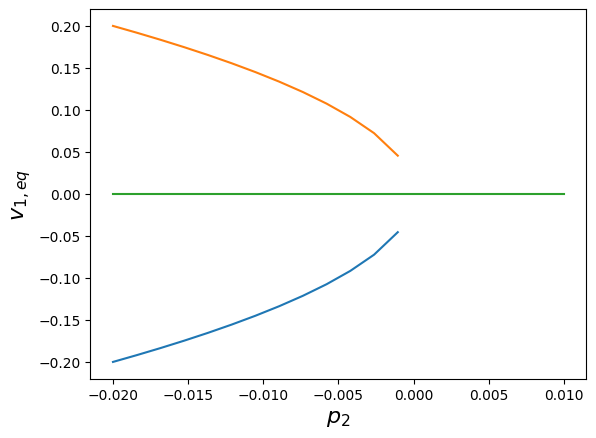

In [32]:
eq_pts_v1 = np.array(eq_pts_v1,dtype=np.complex128)
for root in eq_pts_v1.T:
    plt.plot(
        p2_vals[np.isreal(root)],
        np.real(root[np.isreal(root)])
    )
plt.xlabel("$p_2$",fontsize=16)
plt.ylabel("$v_{1,eq}$",fontsize=16)

An alternative approach is to instead deal with analytic expressions for our equations of motion that retain $p_2$ as a free variable. We will use `sympy`'s substitution capabilities in order to derive these:

In [33]:
params = h_final_reduced.H_params.copy()
params.pop(p2) # remove p2 from substitution rule
hamiltonian = h_final_reduced.H.xreplace(params)
equations_of_motion = h_final_reduced.flow.xreplace(params)
jacobian = h_final_reduced.jacobian.xreplace(params)
display(equations_of_motion)
display(jacobian)

⎡                                            3                        2        ↪
⎢-120.968176157378⋅p₂⋅u₁ - 60.484088078689⋅u₁  - 60.484088078689⋅u₁⋅v₁  - 0.00 ↪
⎢                                                                              ↪
⎢                                           2                        3         ↪
⎣120.968176157378⋅p₂⋅v₁ + 60.484088078689⋅u₁ ⋅v₁ + 60.484088078689⋅v₁  + 0.001 ↪

↪                   ⎤
↪ 343974822718299⋅u₁⎥
↪                   ⎥
↪                   ⎥
↪ 99437708594305⋅v₁ ⎦

⎡                                                                              ↪
⎢                               -120.968176157378⋅u₁⋅v₁                        ↪
⎢                                                                              ↪
⎢                                        2                      2              ↪
⎣120.968176157378⋅p₂ + 60.484088078689⋅u₁  + 181.452264236067⋅v₁  + 0.00199437 ↪

↪                                                      2                     2 ↪
↪            -120.968176157378⋅p₂ - 181.452264236067⋅u₁  - 60.484088078689⋅v₁  ↪
↪                                                                              ↪
↪                                                                              ↪
↪ 708594305                                  120.968176157378⋅u₁⋅v₁            ↪

↪                       ⎤
↪  - 0.00343974822718299⎥
↪                       ⎥
↪                       ⎥
↪                       ⎦

We can determine the precise value of $p_2$ at which the bifurcation occurs by using the discriminant of our polynmial equation of motion for $du_1/dt$:

In [34]:
eqn = sp.discriminant(equations_of_motion[1].xreplace({u1:0}),v1)
display(eqn)
discriminant_roots = sp.solve(sp.discriminant(equations_of_motion[1].xreplace({u1:0}),v1),p2,real=True)
# the first, real-valued root is the value at which our Hamiltonian exhibits a bifurcation 
discriminant_roots

                     3                      2                                  ↪
- 428266916.874425⋅p₂  - 21182.2419618187⋅p₂  - 0.349227204538422⋅p₂ - 1.91921 ↪

↪             
↪ 202375643e-6

[-1.64870683721466e-5, -1.64866529089407e-5 - 2.39866455750574e-10⋅ⅈ, -1.64866 ↪

↪ 529089407e-5 + 2.39866455750574e-10⋅ⅈ]

In [35]:
# the first, real-valued root is the value at which our Hamiltonian exhibits a bifurcation 
p2crit = float(discriminant_roots[0])

### mapping the separatrix to orbital elements
As our final example, we'll use our Hamiltonian model to map the separatrix of the 5:3 MMR in the space of $\Delta =\frac{3}{5}\frac{P_2}{P_1} -1 $ versus $Z = |fe_1e^{i\varpi_1} +ge_2e^{i\varpi_2} | / \sqrt{f^2 + g^2}$. 

The first step is to solve for the locations of the elliptic and hyperbolic fixed point for each value of $p_2$. Once we've determined the location of the hyperbolic fixed point, we can find where the separatrix crosses $u_1=0$ by solving the equation
$$
H(v_1,0) = H(0,u_{1,sx)
$$
for $v_1$. This has two solutions, one interior and one exterior to the elliptic fixed point at $(v_1,u_1) = (v_{1,ell},0)$. We solve for the appropriate points in the loop below by using sympy's `lambdify` to create functions and scipy's `root_scalar`. (Since all our equations are polynomials, we could use alternative methods that simply find polynomical roots, but the root-finding gets the job done just fine...)

In [36]:
from scipy.optimize import root_scalar

v1dot_fn = sp.lambdify((v1,u1,p2),equations_of_motion[0])
dv1dot_du1_fn= sp.lambdify((v1,u1,p2),sp.diff(equations_of_motion[0],u1))

u1dot_fn = sp.lambdify((v1,u1,p2),equations_of_motion[1])
du1dot_dv1_fn = sp.lambdify((v1,u1,p2),sp.diff(equations_of_motion[1],v1))

ham_fn = sp.lambdify((v1,u1,p2),hamiltonian)
p2vals = np.linspace(p2crit-0.003,-0.02)
u1_hyp,v1_ell,v1_sx_minus,v1_sx_plus = np.zeros((4,p2vals.size))

guess = 0.08
for i,p2val in enumerate(p2vals):
    guess = root_scalar(lambda x: u1dot_fn(x,0,p2val),x0=guess,fprime= lambda x: du1dot_dv1_fn(x,0,p2val)).root
    v1_ell[i] = guess
    u1_hyp[i] = root_scalar(lambda x: v1dot_fn(0,x,p2val),x0=guess,fprime= lambda x: dv1dot_du1_fn(0,x,p2val)).root
    Esx = ham_fn(0,u1_hyp[i],p2val)
    v1_sx_plus[i] = root_scalar(
        lambda x: Esx - ham_fn(x,0,p2val), 
        bracket = [v1_ell[i],2*v1_ell[i]]
    ).root
    v1_sx_minus[i] = root_scalar(
        lambda x: Esx - ham_fn(x,0,p2val), 
        bracket = [0,v1_ell[i]]
    ).root

First let's view the fixed point and surrounding separatrix in $v_1$ versus $p_2$ space:

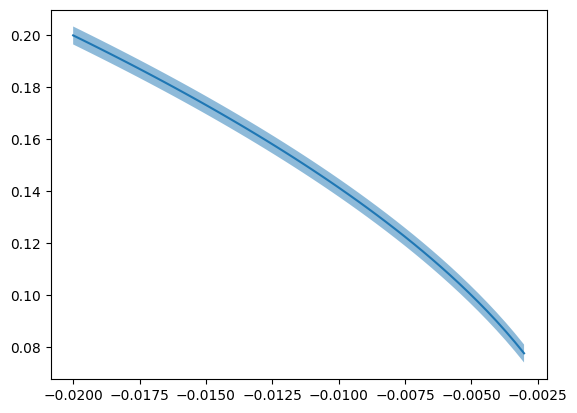

In [37]:
plt.plot(p2vals,v1_ell)
plt.fill_between(p2vals,v1_sx_plus,v1_sx_minus,alpha=0.5)

Now we can map our solutions back to orbital elements and plot the resonance there:

In [38]:
full_vals = h_final_reduced.full_values
i_p2 = h_final_reduced.full_qp_vars.index(p2)
i_u1 = h_final_reduced.full_qp_vars.index(u1)
i_v1 = h_final_reduced.full_qp_vars.index(v1)
pvars = pham.state
Delta_eq,Delta_plus,Delta_minus = np.zeros((3,p2vals.size))
Z_eq,Z_plus,Z_minus = np.zeros((3,p2vals.size))
Nf,Ng = get_fg_coefficients(5,2)
for i,(p2val,v1_eq,v1_sxp,v1_sxm) in enumerate(zip(p2vals,v1_ell,v1_sx_plus,v1_sx_minus)):
    full_vals[i_p2] = p2val
    full_vals[i_u1] = 0.0
    

    # # equlibirum
    full_vals[i_v1] = v1_eq
    # some annoying nans and complex-types cropping up; wrap with np.real and nan_to_num
    pvars.values = np.nan_to_num(np.real(ct_composite.new_to_old_array(full_vals)))
    pl1,pl2 = pvars.particles[1:]
    Delta_eq[i] = (3/5) * pl2.P / pl1.P - 1
    Z_eq[i] = np.abs( Nf * pl1.e * np.exp(1j * pl1.pomega) + Ng * pl2.e * np.exp(1j * pl2.pomega)) / np.sqrt(Nf*Nf+Ng*Ng)

    # 'plus' branch
    full_vals[i_v1] = v1_sxp
    pvars.values = np.real(ct_composite.new_to_old_array(full_vals))
    pl1,pl2 = pvars.particles[1:]
    Delta_plus[i] = (3/5) * pl2.P / pl1.P - 1
    Z_plus[i] = np.abs( Nf * pl1.e * np.exp(1j * pl1.pomega) + Ng * pl2.e * np.exp(1j * pl2.pomega)) / np.sqrt(Nf*Nf+Ng*Ng)


    # 'minus' branch
    full_vals[i_v1] = v1_sxm
    pvars.values = np.real(ct_composite.new_to_old_array(full_vals)) # 
    pl1,pl2 = pvars.particles[1:]
    Delta_minus[i] = (3/5) * pl2.P / pl1.P - 1
    Z_minus[i] = np.abs( Nf * pl1.e * np.exp(1j * pl1.pomega) + Ng * pl2.e * np.exp(1j * pl2.pomega)) / np.sqrt(Nf*Nf+Ng*Ng)


Text(0.5, 1.0, '5:3 MMR')

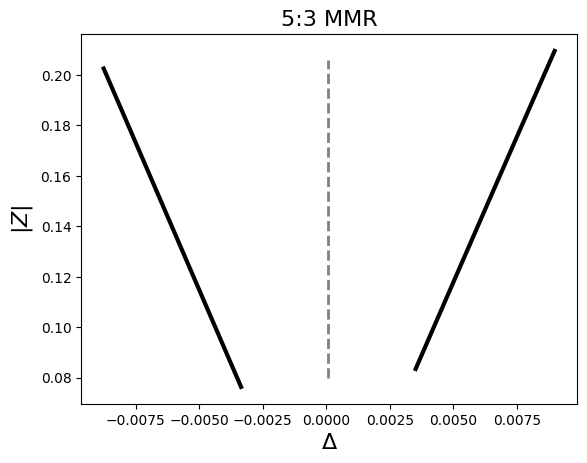

In [39]:
plt.plot(Delta_eq,Z_eq,color='gray',lw=2,ls='--')
plt.plot(Delta_plus,Z_plus,color='k',lw=3)
plt.plot(Delta_minus,Z_minus,color='k',lw=3)
plt.xlabel(r"$\Delta$",fontsize=16)
plt.ylabel(r"$|Z|$",fontsize=16)
plt.title("5:3 MMR",fontsize=16)